# Lab 4-02：不用圖資料庫，手寫圖檢索與多跳查詢

**目標**：把上一本存下的三元組建成 networkx 圖，親手寫出「從問題找到實體 → 沿著邊走幾步 → 把子圖念成文字 → 交給 LLM 回答」。

**你會學到**
- 圖就是「節點＋有方向、有型別的邊」，用 Python 的 dict 就裝得下
- 多跳查詢＝BFS：一步一步往外走
- 超級節點：一個大團體會把整張圖拉進來，要有展開規則
- 子圖轉成句子，才是 LLM 讀得懂的上下文

**前置**：Lab 4-01 已產生 `data/triples.json`（資料夾裡已附一份，可以直接跑）。

**對應投影片**：「從向量到圖：搭橋」「向量 RAG 答不了的兩種題」「Local Search 實體入口」「Lab 4 多跳提問流程」

![圖檢索流程](images/graph_bfs.jpg)

*圖：由左往右讀。先在問題裡找出實體（騙人布），再沿著朱紅色的邊走：騙人布 → 父親耶穌布 → 紅髮海賊團 ← 船長香克斯；走到的子圖轉成文字，交給 LLM 回答。*

## Step 1：先看沒有圖的時候

直接問模型一個要串三件事才答得出來的問題。

In [1]:
from course_utils.llm import chat

QUESTION = "騙人布的父親所在海賊團的船長是誰？"
print(chat([{"role": "user", "content": QUESTION + "用一句話回答。"}]))

騙人布的父親是海賊王索隆的船長，即四皇之首卡爾卡斯。


3B 模型對海賊王的知識很零碎，答案通常是錯的，而且講得很有自信。
模組 3 的做法是撈段落給它看；這一本換個方式：把知識整理成圖，讓程式沿著關係走。

## Step 2：讀三元組，建圖

networkx 的 `MultiDiGraph`：有方向（魯夫 → 草帽海賊團），而且兩個節點之間可以有多條不同關係的邊。
節點屬性 `label` 是類型（Person、Crew…），邊屬性 `relation` 是關係名稱。

In [2]:
import json
from pathlib import Path

import networkx as nx

data = json.loads(Path("data/triples.json").read_text(encoding="utf-8"))

G = nx.MultiDiGraph()
for node in data["nodes"]:
    G.add_node(node["name"], label=node["label"], aliases=node["aliases"])
for t in data["triples"]:
    G.add_edge(t["subject"], t["object"], relation=t["relation"])

print(f"{G.number_of_nodes()} 個節點，{G.number_of_edges()} 條邊")
print("魯夫：", G.nodes["魯夫"])

46 個節點，47 條邊
魯夫： {'label': 'Person', 'aliases': ['蒙其·D·魯夫', '草帽小子']}


## Step 3：把整張圖畫出來

顏色對應類型，跟投影片「Lab 4 圖譜長相」一致：藍＝人物、黃＝海賊團、紅＝寶物；另外兩種是夢想與地方。

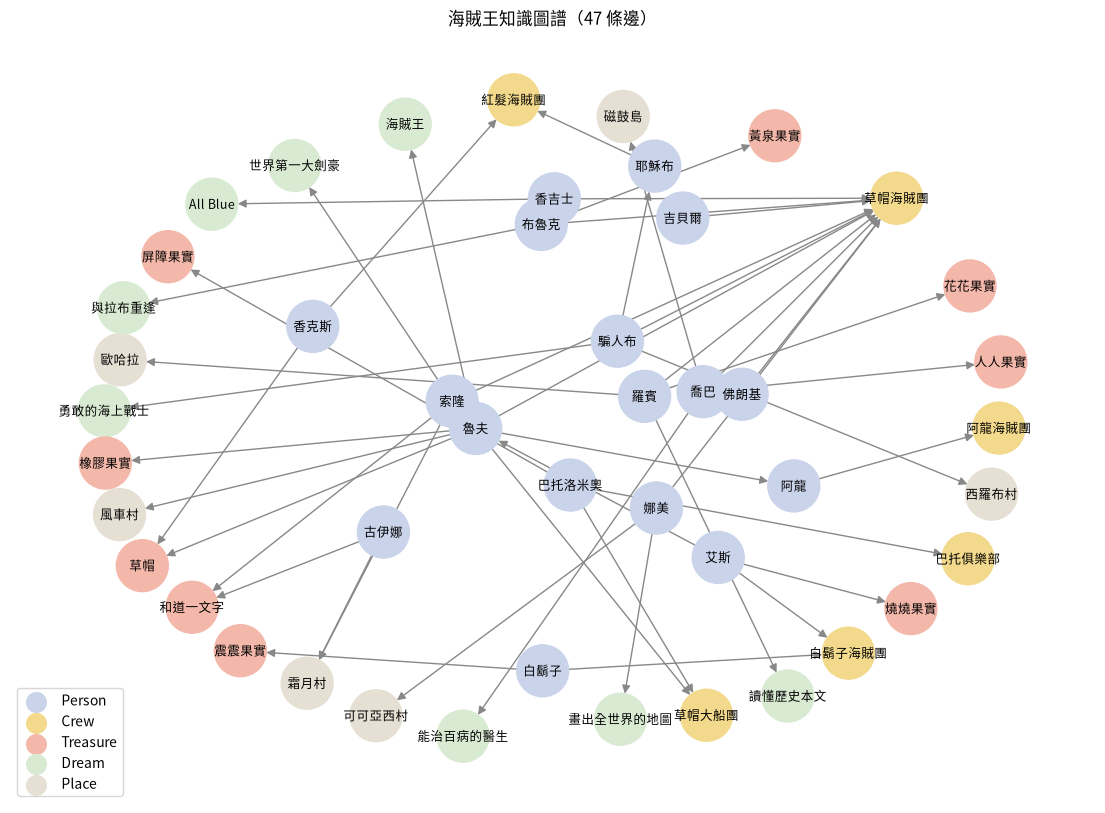

In [3]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

COLORS = {"Person": "#c9d3ea", "Crew": "#f2d98b", "Treasure": "#f4b8aa", "Dream": "#d9ead3", "Place": "#e6e0d4"}

pos = nx.spring_layout(G, seed=7, k=1.6, iterations=200)  # k 越大節點越分散
plt.figure(figsize=(14, 10))
nx.draw_networkx_nodes(G, pos, node_color=[COLORS[G.nodes[n]["label"]] for n in G], node_size=1400)
nx.draw_networkx_labels(G, pos, font_size=9, font_family=plt.rcParams["font.sans-serif"][0])
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=12, edge_color="#888", node_size=1400)
for label, color in COLORS.items():
    plt.scatter([], [], c=color, s=200, label=label)
plt.legend(loc="lower left")
plt.axis("off")
plt.title(f"海賊王知識圖譜（{G.number_of_edges()} 條邊）")
plt.show()

一眼就能看出「草帽海賊團」是中心：幾乎每個船員都連到它。這個觀察在 Step 7 會變成一個問題。

## Step 4：一跳——某個節點連出去、連進來的邊

圖檢索最小的動作：給一個節點，列出它所有的邊。出邊是「它做了什麼」，入邊是「誰對它做了什麼」。

In [4]:
def neighbors(node: str) -> None:
    for _, v, d in G.out_edges(node, data=True):
        print(f"  {node} -[{d['relation']}]-> {v}")
    for u, _, d in G.in_edges(node, data=True):
        print(f"  {u} -[{d['relation']}]-> {node}")


print("魯夫：")
neighbors("魯夫")
print("紅髮海賊團：")
neighbors("紅髮海賊團")

魯夫：
  魯夫 -[FROM]-> 風車村
  魯夫 -[OWNS]-> 橡膠果實
  魯夫 -[CAPTAIN_OF]-> 草帽海賊團
  魯夫 -[OWNS]-> 草帽
  魯夫 -[DREAMS_OF]-> 海賊王
  魯夫 -[DEFEATED]-> 阿龍
  魯夫 -[CAPTAIN_OF]-> 草帽大船團
  艾斯 -[BROTHER_OF]-> 魯夫
紅髮海賊團：
  香克斯 -[CAPTAIN_OF]-> 紅髮海賊團
  耶穌布 -[MEMBER_OF]-> 紅髮海賊團


## Step 5：兩跳——和魯夫同一個海賊團的還有誰？

投影片上的例子：魯夫 → 草帽海賊團 ← 索隆。寫成程式就是兩層迴圈：
先找魯夫連到哪些海賊團，再找誰也連到那個海賊團。

In [5]:
CREW_RELATIONS = {"CAPTAIN_OF", "MEMBER_OF"}

for _, crew, d in G.out_edges("魯夫", data=True):
    if d["relation"] not in CREW_RELATIONS:
        continue
    mates = [u for u, _, d2 in G.in_edges(crew, data=True) if d2["relation"] in CREW_RELATIONS and u != "魯夫"]
    print(f"{crew}：{'、'.join(mates)}")

草帽海賊團：索隆、娜美、騙人布、香吉士、喬巴、羅賓、佛朗基、布魯克、吉貝爾
草帽大船團：巴托洛米奧


向量檢索要撈到「提到索隆的段落」和「提到魯夫的段落」兩塊，再靠模型自己拼；
圖只要沿著邊走兩步，答案就在手上，而且一個都不會漏。

但每種問題都寫一個專用迴圈太累。下一步寫一個通用的版本。

## Step 6：通用的多跳——BFS

從起點開始，一圈一圈往外：第 1 步拿起點的所有邊，第 2 步拿第 1 步新碰到的節點的所有邊……
這就是課本上的廣度優先搜尋，只是我們把走過的邊記下來。

In [6]:
def bfs_edges(starts: list[str], hops: int) -> list[tuple[str, str, str, int]]:
    seen, frontier, edges = set(starts), list(starts), []
    for hop in range(1, hops + 1):
        nxt = []
        for node in frontier:
            for u, v, d in list(G.out_edges(node, data=True)) + list(G.in_edges(node, data=True)):
                edge = (u, d["relation"], v)
                if edge in [e[:3] for e in edges]:
                    continue
                edges.append((*edge, hop))
                other = v if u == node else u
                if other not in seen:
                    seen.add(other)
                    nxt.append(other)
        frontier = nxt
    return edges


for hops in [1, 2, 3]:
    sub = bfs_edges(["騙人布"], hops)
    print(f"走 {hops} 步：{len(sub)} 條邊")

走 1 步：4 條邊
走 2 步：14 條邊
走 3 步：36 條邊


答案（香克斯）在第 3 步：騙人布 → 耶穌布 → 紅髮海賊團 ← 香克斯。
可是走 3 步時，子圖幾乎是整張圖。為什麼？

## Step 7：先看它壞掉——超級節點

騙人布第 1 步就碰到「草帽海賊團」，第 2 步從它展開，就把十個船員全拉進來，
第 3 步再把每個船員的果實、夢想、故鄉都拉進來。這種連著一大堆邊的節點叫**超級節點**（hub）。

塞整張圖給 LLM，等於回到「把全部文件塞進 prompt」：貴，而且小模型會被無關的事實干擾。

In [7]:
degree = sorted(((G.degree(n), n) for n in G), reverse=True)[:6]
for d, n in degree:
    print(f"{n}：{d} 條邊")

草帽海賊團：10 條邊
魯夫：8 條邊
騙人布：4 條邊
羅賓：4 條邊
索隆：4 條邊
喬巴：4 條邊


修法是加一條展開規則：**走到海賊團，只往它的船長走，不展開全部成員。**
這條規則來自我們對問題的理解：多跳問題問的通常是「某人所屬團體的船長」，很少問「那個團的所有人」。
真實系統的規則五花八門（限制度數、按關係類型挑、按相關性排序），重點是一定要有。

In [8]:
def bfs_edges_pruned(starts: list[str], hops: int) -> list[tuple[str, str, str, int]]:
    seen, frontier, edges = set(starts), list(starts), []
    for hop in range(1, hops + 1):
        nxt = []
        for node in frontier:
            is_crew = G.nodes[node]["label"] == "Crew"
            for u, v, d in list(G.out_edges(node, data=True)) + list(G.in_edges(node, data=True)):
                if is_crew and v == node and d["relation"] != "CAPTAIN_OF":
                    continue  # 海賊團只往船長走
                edge = (u, d["relation"], v)
                if edge in [e[:3] for e in edges]:
                    continue
                edges.append((*edge, hop))
                other = v if u == node else u
                if other not in seen:
                    seen.add(other)
                    nxt.append(other)
        frontier = nxt
    return edges


sizes = {"全部展開": [], "海賊團只找船長": []}
for hops in range(1, 5):
    sizes["全部展開"].append(len(bfs_edges(["騙人布"], hops)))
    sizes["海賊團只找船長"].append(len(bfs_edges_pruned(["騙人布"], hops)))
print(sizes)

{'全部展開': [4, 14, 36, 43], '海賊團只找船長': [4, 6, 14, 18]}


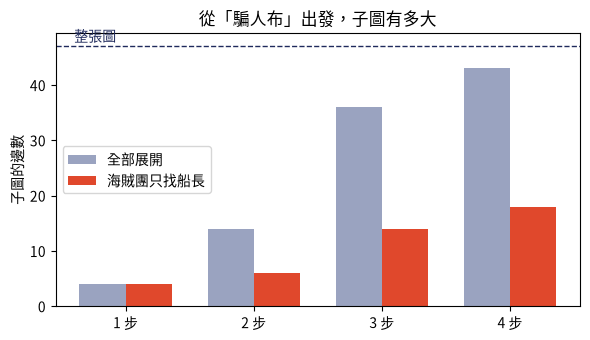

In [9]:
import numpy as np

x = np.arange(1, 5)
plt.figure(figsize=(6, 3.5))
plt.bar(x - 0.18, sizes["全部展開"], width=0.36, label="全部展開", color="#9aa3c0")
plt.bar(x + 0.18, sizes["海賊團只找船長"], width=0.36, label="海賊團只找船長", color="#e0482c")
plt.axhline(G.number_of_edges(), ls="--", c="#1f2a5c", lw=1)
plt.text(0.6, G.number_of_edges() + 1, "整張圖", color="#1f2a5c")
plt.xticks(x, [f"{h} 步" for h in x])
plt.ylabel("子圖的邊數")
plt.title("從「騙人布」出發，子圖有多大")
plt.legend()
plt.tight_layout()
plt.show()

## Step 8：畫出走到的子圖

把剪枝後走 3 步的子圖畫出來，從起點到答案的那條路用朱紅色標出。

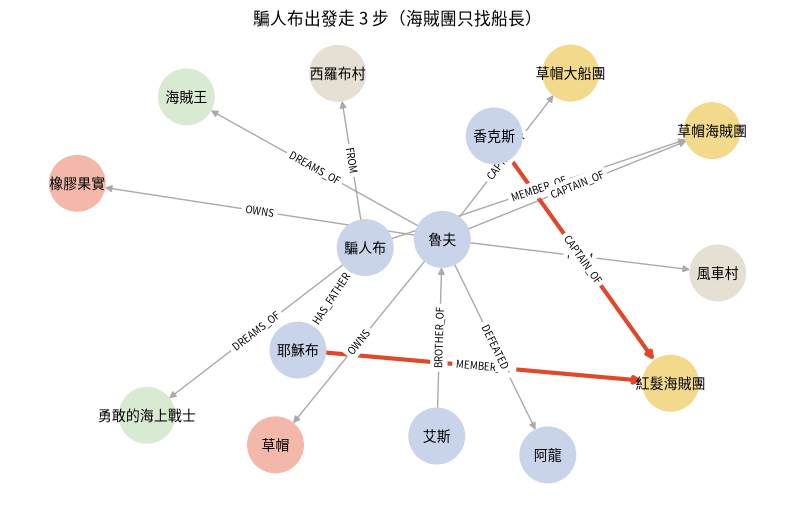

In [10]:
sub_edges = bfs_edges_pruned(["騙人布"], 3)
H = nx.DiGraph()  # 子圖裡同一對節點最多一條邊，用簡單有向圖比較好畫
for s, r, o, hop in sub_edges:
    H.add_edge(s, o, relation=r)

path = [("騙人布", "耶穌布"), ("耶穌布", "紅髮海賊團"), ("香克斯", "紅髮海賊團")]
pos = nx.spring_layout(H, seed=3, k=1.2)
plt.figure(figsize=(10, 6))
nx.draw_networkx_nodes(H, pos, node_color=[COLORS[G.nodes[n]["label"]] for n in H], node_size=1600)
nx.draw_networkx_labels(H, pos, font_size=10, font_family=plt.rcParams["font.sans-serif"][0])
nx.draw_networkx_edges(H, pos, edge_color=["#e0482c" if (u, v) in path else "#aaa" for u, v in H.edges()],
                       width=[3 if (u, v) in path else 1 for u, v in H.edges()], arrows=True, node_size=1600)
nx.draw_networkx_edge_labels(H, pos, edge_labels={(u, v): d["relation"] for u, v, d in H.edges(data=True)}, font_size=7)
plt.axis("off")
plt.title("騙人布出發走 3 步（海賊團只找船長）")
plt.show()

## Step 9：子圖念成句子

LLM 讀 `(騙人布, HAS_FATHER, 耶穌布)` 也懂，但 3B 小模型讀自然的中文句子準得多。
每種關係配一個句型就好。順序照 BFS 的步數排，離問題越近的事實越前面。

In [11]:
PHRASES = {
    "CAPTAIN_OF": "{s} 是 {o} 的船長（帶頭的人）",
    "MEMBER_OF": "{s} 是 {o} 的成員",
    "OWNS": "{s} 擁有 {o}",
    "DREAMS_OF": "{s} 的夢想是 {o}",
    "FROM": "{s} 出身 {o}",
    "HAS_FATHER": "{s} 的父親是 {o}",
    "BROTHER_OF": "{s} 是 {o} 的結拜哥哥",
    "DEFEATED": "{s} 打倒了 {o}",
}


def to_text(edges: list[tuple]) -> str:
    return "\n".join(PHRASES[r].format(s=s, o=o) for s, r, o, *_ in edges)


print(to_text(sub_edges))

騙人布 出身 西羅布村
騙人布 是 草帽海賊團 的成員
騙人布 的夢想是 勇敢的海上戰士
騙人布 的父親是 耶穌布
魯夫 是 草帽海賊團 的船長（帶頭的人）
耶穌布 是 紅髮海賊團 的成員
魯夫 出身 風車村
魯夫 擁有 橡膠果實
魯夫 擁有 草帽
魯夫 的夢想是 海賊王
魯夫 打倒了 阿龍
魯夫 是 草帽大船團 的船長（帶頭的人）
艾斯 是 魯夫 的結拜哥哥
香克斯 是 紅髮海賊團 的船長（帶頭的人）


## Step 10：從問題找到起點

投影片「Local Search」用向量比對實體描述來找入口。我們的圖很小，用字串比對就夠：
問題裡出現了哪個節點的名字或別名，那個節點就是起點。

要小心一件事：問題提到「白鬍子海賊團」時，「白鬍子」也會被比對到。規則是**被更長名字蓋住的短名字不算**。

In [12]:
def link_entities(question: str) -> list[str]:
    hits = {}
    for name, attrs in G.nodes(data=True):
        for surface in [name, *attrs["aliases"]]:
            if surface in question:
                hits[surface] = name
    surfaces = [s for s in hits if not any(s != o and s in o for o in hits)]
    return sorted({hits[s] for s in surfaces})


for q in [QUESTION, "打倒阿龍的人，夢想是什麼？", "草帽小子出身哪裡？", "白鬍子海賊團的船長是誰？"]:
    print(q, "→", link_entities(q))

騙人布的父親所在海賊團的船長是誰？ → ['騙人布']
打倒阿龍的人，夢想是什麼？ → ['阿龍']
草帽小子出身哪裡？ → ['魯夫']
白鬍子海賊團的船長是誰？ → ['白鬍子海賊團']


「草帽小子」靠的是 Lab 4-01 存下的別名；沒有那張別名表，這個問題就找不到起點。

## Step 11：全部串起來

問題 → 找起點 → 剪枝 BFS → 念成句子 → 交給 LLM。整個流程模型只出場一次（最後組答案），
中間「找誰、走哪」都是確定的程式，可以重跑、可以除錯。

In [13]:
ANSWER_SYSTEM = "只根據提供的資料回答，用一句話。資料沒有就說「資料不足」。"


def graph_answer(question: str, hops: int = 4, verbose: bool = False) -> str:
    starts = link_entities(question)
    context = to_text(bfs_edges_pruned(starts, hops))
    if verbose:
        print(f"起點：{starts}，上下文 {len(context.splitlines())} 句")
    return chat([
        {"role": "system", "content": ANSWER_SYSTEM},
        {"role": "user", "content": f"資料：\n{context}\n\n問題：{question}"},
    ])


print(graph_answer(QUESTION, verbose=True))

起點：['騙人布']，上下文 18 句
騙人布的父親耶穌布是紅髮海賊團的船長。


In [14]:
for q in ["和索隆同一個海賊團的船長，夢想是什麼？", "打倒阿龍的人，夢想是什麼？", "巴托洛米奧所屬大船團的帶頭人，出身哪個村子？"]:
    print(q)
    print("  →", graph_answer(q, verbose=True))

和索隆同一個海賊團的船長，夢想是什麼？
起點：['索隆']，上下文 18 句
  → 魯夫，他的夢想是海賊王。因此，和索隆同一個海賈團的船長，夢想是海賊王。
打倒阿龍的人，夢想是什麼？
起點：['阿龍']，上下文 14 句
  → 打倒阿龍的人，夢想是海賊王。根據提供的資料，這個人是魯夫。
巴托洛米奧所屬大船團的帶頭人，出身哪個村子？
起點：['巴托洛米奧']，上下文 15 句
  → 資料不足。


檢索這一半是穩的：答案需要的事實一定在上下文裡（你可以印出 `graph_context` 自己確認）。
剩下的錯誤來自 3B 模型讀了十幾句之後還是串錯，這是「生成」的問題，不是「檢索」的問題。
Lab 4-04 會用 12 題把兩種檢索正式比一次。

上面寫的函式整理在同資料夾的 `graph_retrieval.py`，Lab 4-04 直接 import。

## 試試看

1. 把 `bfs_edges_pruned` 換回 `bfs_edges`（不剪枝）再問一次 `QUESTION`。上下文變多少句？答案有變嗎？
2. 問「和魯夫同一個海賊團的人有誰？」。剪枝規則讓它答不出來，為什麼？你會怎麼讓兩種問題都能答？（提示：Step 5 的專用迴圈）
3. 把 `PHRASES` 換成直接印 `(主體, 關係, 客體)`，比較同一題的回答。

## 小結

- 圖檢索的核心只有三步：從問題找起點、沿著邊走、把走到的子圖念成文字。
- 多跳＝BFS；但遇到超級節點一定要有展開規則，否則子圖會變成整張圖。
- 手寫版適合理解，資料一大就需要真正的圖資料庫。下一本把同一份三元組匯入 Neo4j，用 Cypher 查。